# Tutorial 7 (a)

# Simple Exponential Smoothing

In [1]:
# Load all related libraries
import esFunctions as es
import pandas as pd
import numpy as np
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import axes

import warnings
warnings.filterwarnings('ignore') # We can suppress the warnings

In [2]:
# Load the data file
ibm_df = pd.read_csv('ibm-common-stock-closing-prices.csv')

# Display the first five records
ibm_df.head()

,Date,IBM common stock closing prices
0,1962-01-02,572.00
1,1962-01-03,577.00
2,1962-01-04,571.25
3,1962-01-05,560.00
4,1962-01-08,549.50


In [3]:
# Replace long heading of the column with short heading
ibm_df.rename(columns={'IBM common stock closing prices': 'Close_Price'}, inplace = True)

# Display the first five records
ibm_df.head()

,Date,Close_Price
0,1962-01-02,572.00
1,1962-01-03,577.00
2,1962-01-04,571.25
3,1962-01-05,560.00
4,1962-01-08,549.50


In [8]:
# Add a new column (SES) in the dataframe
ibm_df['SES'] = es.single_exp_smoothing(ibm_df['Close_Price'], 0.8)

# Display first five records
ibm_df.head()

,Date,Close_Price,SES
0,1962-01-02,572.00,572.000
1,1962-01-03,577.00,576.000
2,1962-01-04,571.25,572.200
3,1962-01-05,560.00,562.440
4,1962-01-08,549.50,552.088


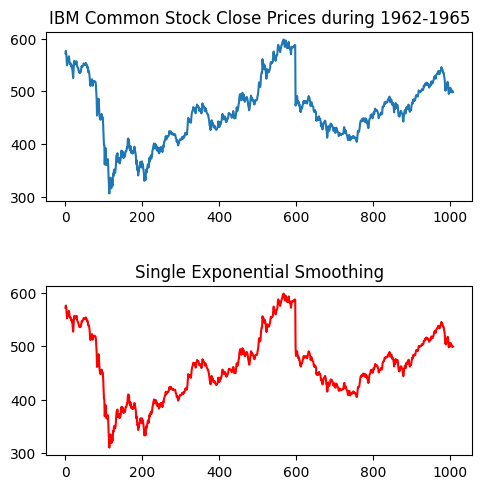

In [9]:
# plot the above dataframe
fig = plt.figure(figsize = (5.5, 5.5))
ax = fig.add_subplot(2, 1, 1)
fig.subplots_adjust(hspace = 0.5)
ibm_df['Close_Price'].plot(ax = ax)
ax.set_title('IBM Common Stock Close Prices during 1962-1965')
ax = fig.add_subplot(2, 1, 2)
ibm_df['SES'].plot(ax = ax, color = 'r')
ax.set_title('Single Exponential Smoothing')

# Save the png file on your folder
plt.savefig('_02_1.png', format = 'png', dpi = 300)
plt.show()

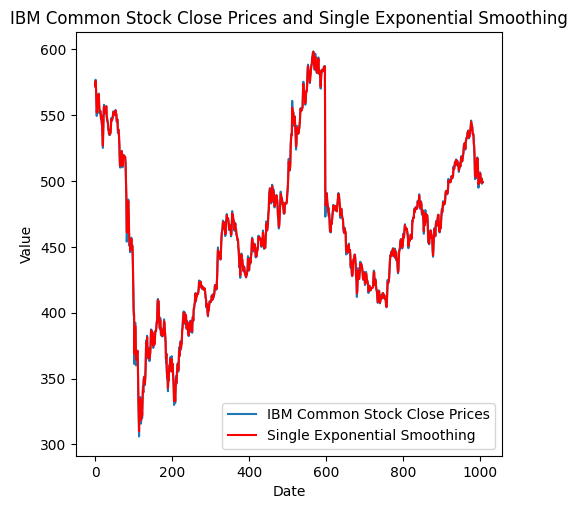

In [10]:
import matplotlib.pyplot as plt

# plot the above dataframe
fig, ax = plt.subplots(figsize = (5.5, 5.5))
fig.subplots_adjust(hspace = 0.5)

ibm_df['Close_Price'].plot(ax = ax, label = 'IBM Common Stock Close Prices')
ibm_df['SES'].plot(ax = ax, color = 'r', label = 'Single Exponential Smoothing')

ax.set_title('IBM Common Stock Close Prices and Single Exponential Smoothing')
ax.set_xlabel('Date')
ax.set_ylabel('Value')
ax.legend()

# Save the png file in your folder
plt.savefig('_02_1.png', format = 'png', dpi =300)
plt.show()

In [11]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import numpy as np

# --- Accuracy metrics ---
def calculate_accuracy(y_true, y_pred):
    df_temp = (
        np.array(y_true).astype(float),
        np.array(y_pred).astype(float)
    )
    # Remove NaN values
    mask = ~np.isnan(df_temp[0]) & ~np.isnan(df_temp[1])
    y_true_clean = df_temp[0][mask]
    y_pred_clean = df_temp[1][mask]

    mse = mean_squared_error(y_true_clean, y_pred_clean)
    mae = mean_absolute_error(y_true_clean, y_pred_clean)
    mape = (abs((y_true_clean - y_pred_clean) / y_true_clean).mean()) * 100
    return mse, mae, mape


In [12]:
# Comapre Single exponential smooting for three values of alpha (0.2, 0.6, 0.8)
ibm_df['SES2'] = es.single_exp_smoothing(ibm_df['Close_Price'], 0.1)
ibm_df['SES6'] = es.single_exp_smoothing(ibm_df['Close_Price'], 0.5)
ibm_df['SES8'] = es.single_exp_smoothing(ibm_df['Close_Price'], 0.9)

In [13]:
# --- Calculate Accuracy ---
mse1, mae1, mape1 = calculate_accuracy(ibm_df['Close_Price'], ibm_df['SES2'])
mse5, mae5, mape5 = calculate_accuracy(ibm_df['Close_Price'], ibm_df['SES6'])
mse9, mae9, mape9 = calculate_accuracy(ibm_df['Close_Price'], ibm_df['SES8'])

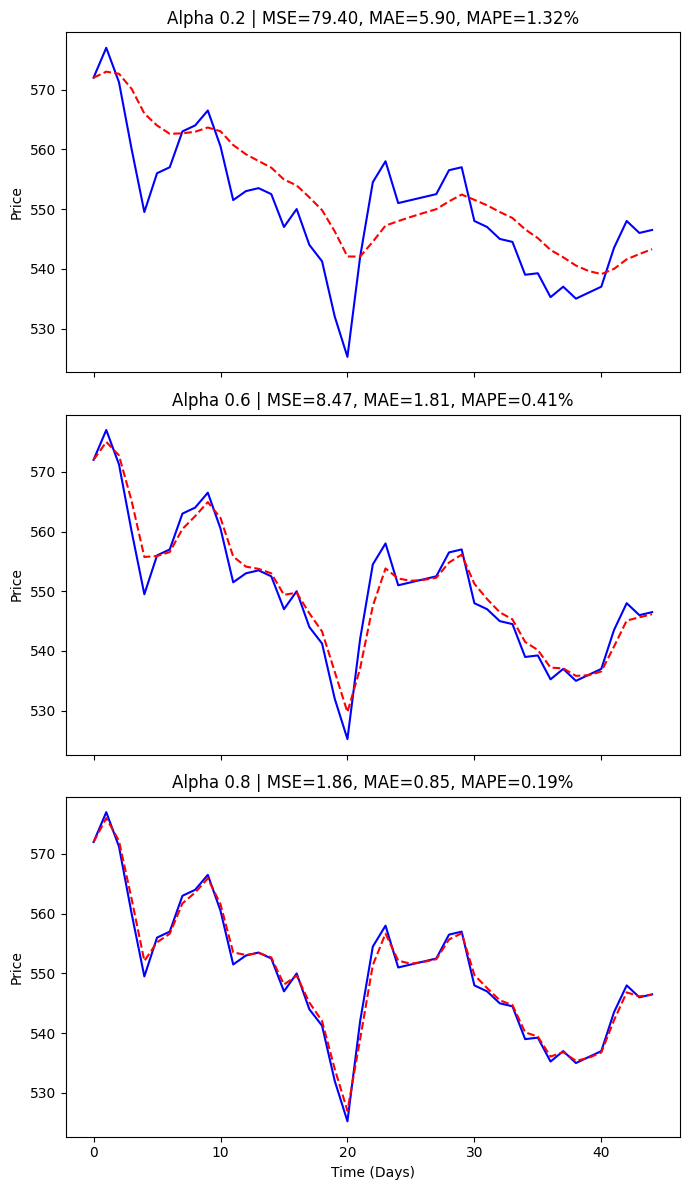

In [14]:
import matplotlib.pyplot as plt

# --- Plot ---
f, axarr = plt.subplots(3, sharex=True)
f.set_size_inches(7, 12)

# Alpha 0.2
ibm_df['Close_Price'].iloc[:45].plot(color='b', linestyle='-', ax=axarr[0])
ibm_df['SES2'].iloc[:45].plot(color='r', linestyle='--', ax=axarr[0])
axarr[0].set_title(f'Alpha 0.2 | MSE={mse2:.2f}, MAE={mae2:.2f}, MAPE={mape2:.2f}%')
axarr[0].set_ylabel("Price")

# Alpha 0.6
ibm_df['Close_Price'].iloc[:45].plot(color='b', linestyle='-', ax=axarr[1])
ibm_df['SES6'].iloc[:45].plot(color='r', linestyle='--', ax=axarr[1])
axarr[1].set_title(f'Alpha 0.6 | MSE={mse6:.2f}, MAE={mae6:.2f}, MAPE={mape6:.2f}%')
axarr[1].set_ylabel("Price")

# Alpha 0.8
ibm_df['Close_Price'].iloc[:45].plot(color='b', linestyle='-', ax=axarr[2])
ibm_df['SES8'].iloc[:45].plot(color='r', linestyle='--', ax=axarr[2])
axarr[2].set_title(f'Alpha 0.8 | MSE={mse8:.2f}, MAE={mae8:.2f}, MAPE={mape8:.2f}%')
axarr[2].set_ylabel("Price")
axarr[2].set_xlabel("Time (Days)")

plt.tight_layout()
plt.savefig('_02_02.png', format='png', dpi=300)
plt.show()

In [15]:
# Comapre Single exponential smooting for three values of alpha (0.2, 0.6, 0.8)
ibm_df['SES2'] = es.single_exp_smoothing(ibm_df['Close_Price'], 0.1)
ibm_df['SES6'] = es.single_exp_smoothing(ibm_df['Close_Price'], 0.5)
ibm_df['SES8'] = es.single_exp_smoothing(ibm_df['Close_Price'], 0.9)

In [16]:
# --- Calculate Accuracy ---
mse1, mae1, mape1 = calculate_accuracy(ibm_df['Close_Price'], ibm_df['SES2'])
mse5, mae5, mape5 = calculate_accuracy(ibm_df['Close_Price'], ibm_df['SES6'])
mse9, mae9, mape9 = calculate_accuracy(ibm_df['Close_Price'], ibm_df['SES8'])

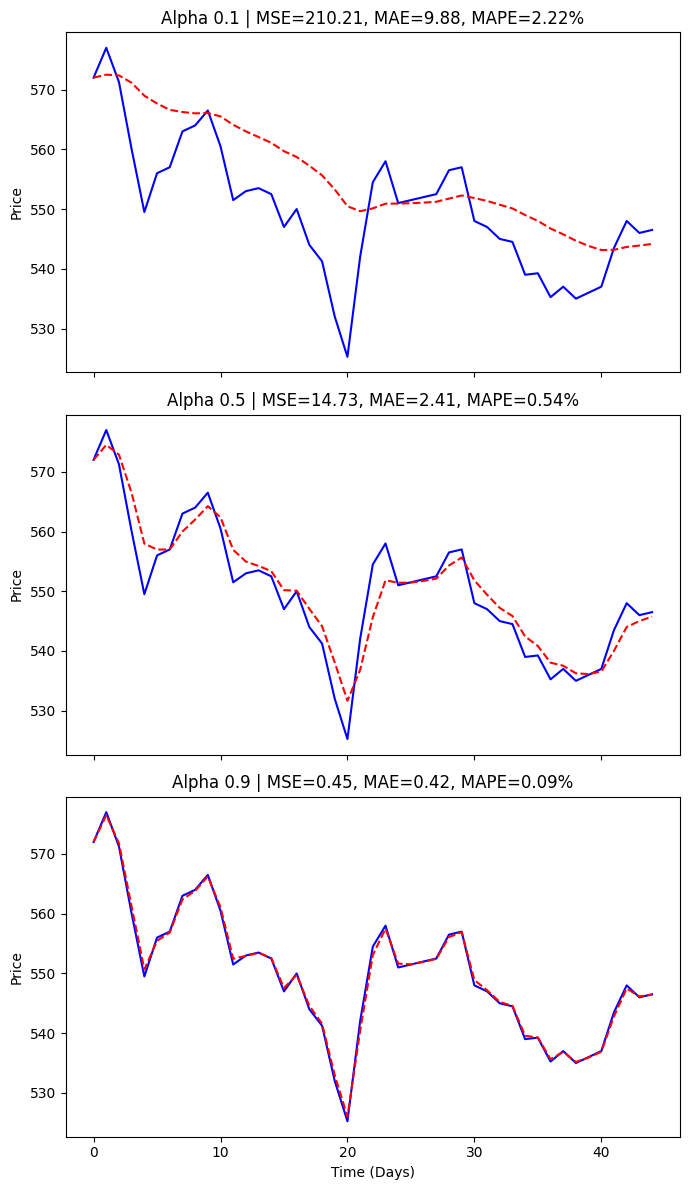

In [20]:
import matplotlib.pyplot as plt

# --- Plot ---
f, axarr = plt.subplots(3, sharex=True)
f.set_size_inches(7, 12)

# Alpha 0.1
ibm_df['Close_Price'].iloc[:45].plot(color='b', linestyle='-', ax=axarr[0])
ibm_df['SES2'].iloc[:45].plot(color='r', linestyle='--', ax=axarr[0])
axarr[0].set_title(f'Alpha 0.1 | MSE={mse1:.2f}, MAE={mae1:.2f}, MAPE={mape1:.2f}%')
axarr[0].set_ylabel("Price")

# Alpha 0.5
ibm_df['Close_Price'].iloc[:45].plot(color='b', linestyle='-', ax=axarr[1])
ibm_df['SES6'].iloc[:45].plot(color='r', linestyle='--', ax=axarr[1])
axarr[1].set_title(f'Alpha 0.5 | MSE={mse5:.2f}, MAE={mae5:.2f}, MAPE={mape5:.2f}%')
axarr[1].set_ylabel("Price")

# Alpha 0.9
ibm_df['Close_Price'].iloc[:45].plot(color='b', linestyle='-', ax=axarr[2])
ibm_df['SES8'].iloc[:45].plot(color='r', linestyle='--', ax=axarr[2])
axarr[2].set_title(f'Alpha 0.9 | MSE={mse9:.2f}, MAE={mae9:.2f}, MAPE={mape9:.2f}%')
axarr[2].set_ylabel("Price")
axarr[2].set_xlabel("Time (Days)")

plt.tight_layout()
plt.savefig('_02_02.png', format='png', dpi=300)
plt.show()

# Double Exponential Smoothing

In [23]:
# Load the dataset
beer_df = pd.read_csv('quarterly-beer-production-in-aus-March 1956-June 1994.csv')

# Display first five records
beer_df.head()

,Quarter,Quarterly beer production in Australia: megalitres. March 1956 ? June 1994
0,1956Q1,284.4
1,1956Q2,212.8
2,1956Q3,226.9
3,1956Q4,308.4
4,1957Q1,262.0


In [24]:
# Replace the long heading of the column with short 
beer_df.rename(columns={'Quarterly beer production in Australia: megalitres. March 1956 ? June 1994': 'Beer_Prod'
                       }, inplace = True)

# Display first five records
beer_df.head()

,Quarter,Beer_Prod
0,1956Q1,284.4
1,1956Q2,212.8
2,1956Q3,226.9
3,1956Q4,308.4
4,1957Q1,262.0


In [25]:
# Check if there is any null values present
missing = (pd.isnull(beer_df['Quarter'])) | (pd.isnull(beer_df['Beer_Prod']))
print('Number of rows with at least one missing values:', missing.sum())
beer_df = beer_df.loc[~missing, :]
print('Shape after removing missing values:', beer_df.shape)

Number of rows with at least one missing values: 1
Shape after removing missing values: (154, 2)


In [26]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# --- Accuracy metrics ---
def calculate_accuracy(y_true, y_pred):
    y_true = np.array(y_true, dtype=float)
    y_pred = np.array(y_pred, dtype=float)
    
    # remove NaNs
    mask = ~np.isnan(y_true) & ~np.isnan(y_pred)
    y_true_clean = y_true[mask]
    y_pred_clean = y_pred[mask]

    mse = mean_squared_error(y_true_clean, y_pred_clean)
    mae = mean_absolute_error(y_true_clean, y_pred_clean)
    mape = (abs((y_true_clean - y_pred_clean) / y_true_clean).mean()) * 100
    return mse, mae, mape

In [27]:
# Calculate the forecast values for different values of alpha and beta
beer_df['DEF00'] = es.double_exp_smoothing(beer_df['Beer_Prod'], 0, 0)
beer_df['DEF01'] = es.double_exp_smoothing(beer_df['Beer_Prod'], 0, 1)
beer_df['DEF10'] = es.double_exp_smoothing(beer_df['Beer_Prod'], 1, 0)
beer_df['DEF11'] = es.double_exp_smoothing(beer_df['Beer_Prod'], 1, 1)

In [28]:
# --- Calculate accuracy for each case ---
mse00, mae00, mape00 = calculate_accuracy(beer_df['Beer_Prod'], beer_df['DEF00'])
mse01, mae01, mape01 = calculate_accuracy(beer_df['Beer_Prod'], beer_df['DEF01'])
mse10, mae10, mape10 = calculate_accuracy(beer_df['Beer_Prod'], beer_df['DEF10'])
mse11, mae11, mape11 = calculate_accuracy(beer_df['Beer_Prod'], beer_df['DEF11'])

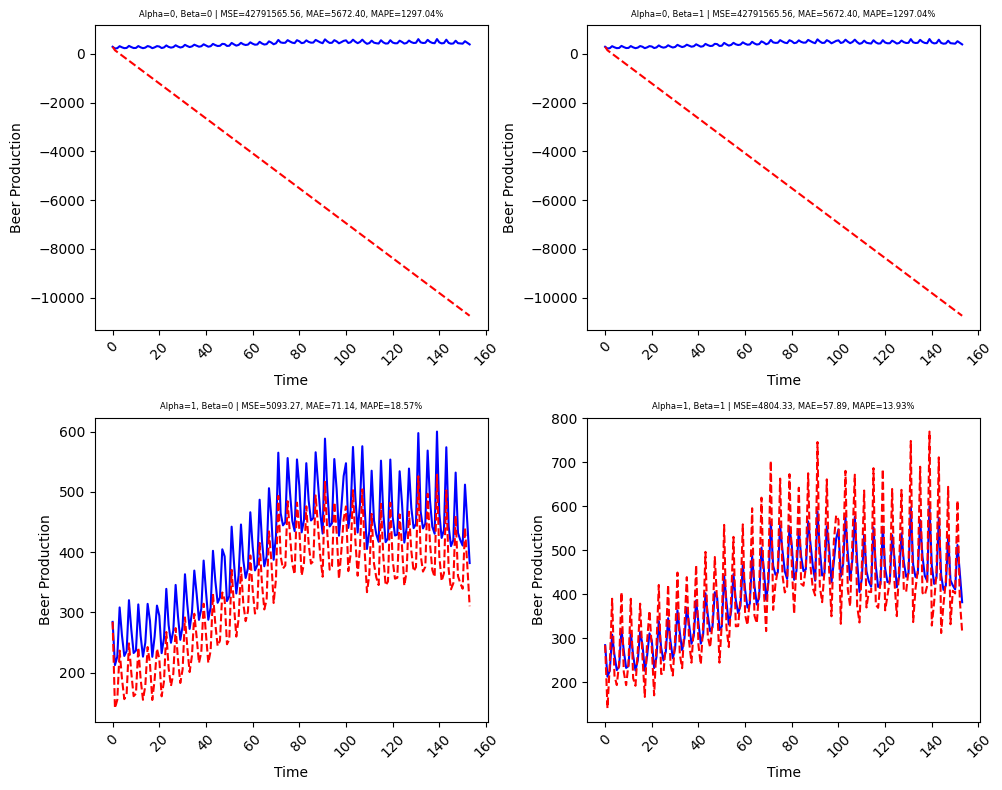

In [29]:
# --- Plot ---
fig = plt.figure(figsize=(10, 8))
fig.subplots_adjust(hspace=.5, wspace=.3)

# Alpha=0, Beta=0
ax = fig.add_subplot(2,2,1)
beer_df['Beer_Prod'].plot(color='b', linestyle = '-', ax=ax)
beer_df['DEF00'].plot(color='r', linestyle = '--', ax=ax)
ax.set_title(f'Alpha=0, Beta=0 | MSE={mse00:.2f}, MAE={mae00:.2f}, MAPE={mape00:.2f}%', fontsize=6)
ax.set_ylabel("Beer Production")
ax.set_xlabel("Time")

# Alpha=0, Beta=1
ax = fig.add_subplot(2,2,2)
beer_df['Beer_Prod'].plot(color='b', linestyle = '-', ax=ax)
beer_df['DEF01'].plot(color='r', linestyle = '--', ax=ax)
ax.set_title(f'Alpha=0, Beta=1 | MSE={mse01:.2f}, MAE={mae01:.2f}, MAPE={mape01:.2f}%', fontsize=6)
ax.set_ylabel("Beer Production")
ax.set_xlabel("Time")

# Alpha=1, Beta=0
ax = fig.add_subplot(2,2,3)
beer_df['Beer_Prod'].plot(color='b', linestyle = '-', ax=ax)
beer_df['DEF10'].plot(color='r', linestyle = '--', ax=ax)
ax.set_title(f'Alpha=1, Beta=0 | MSE={mse10:.2f}, MAE={mae10:.2f}, MAPE={mape10:.2f}%', fontsize=6)
ax.set_ylabel("Beer Production")
ax.set_xlabel("Time")

# Alpha=1, Beta=1
ax = fig.add_subplot(2,2,4)
beer_df['Beer_Prod'].plot(color='b', linestyle = '-', ax=ax)
beer_df['DEF11'].plot(color='r', linestyle = '--', ax=ax)
ax.set_title(f'Alpha=1, Beta=1 | MSE={mse11:.2f}, MAE={mae11:.2f}, MAPE={mape11:.2f}%', fontsize=6)
ax.set_ylabel("Beer Production")
ax.set_xlabel("Time")

# Rotate x labels for better readability
for ax in fig.axes:
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y')

plt.tight_layout()
plt.show()


In [30]:
beer_df['DEF'] = es.double_exp_smoothing(beer_df['Beer_Prod'], 0.4, 0.7)

In [31]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Actual and Forecast values
y_true = beer_df['Beer_Prod']
y_pred = beer_df['DEF']

# Calculate accuracy metrics
mse = mean_squared_error(y_true, y_pred)
mae = mean_absolute_error(y_true, y_pred)
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

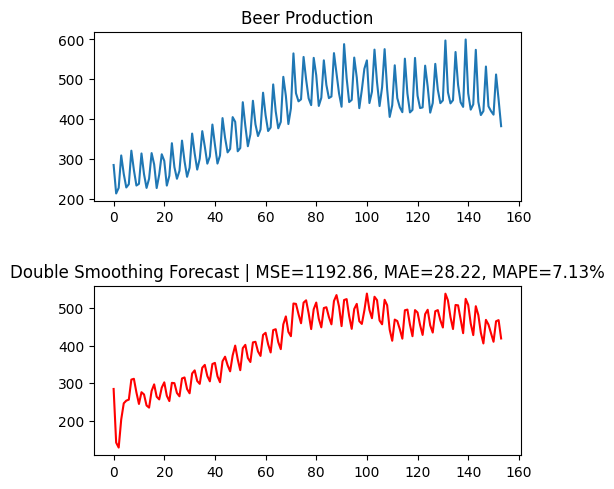

In [32]:
fig = plt.figure(figsize=(5.5, 5.5))
fig.subplots_adjust(hspace=0.5)

# Original data
ax = fig.add_subplot(2, 1, 1)
beer_df['Beer_Prod'].plot(ax=ax)
ax.set_title('Beer Production')

# Forecast
ax = fig.add_subplot(2, 1, 2)
beer_df['DEF'].plot(ax=ax, color='r')
ax.set_title(f'Double Smoothing Forecast | MSE={mse:.2f}, MAE={mae:.2f}, MAPE={mape:.2f}%')

plt.show()


In [33]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# --- Forecasts ---
# SES with alpha=0.4
beer_df['SES'] = es.single_exp_smoothing(beer_df['Beer_Prod'], 0.4)

# DES with alpha=0.4, beta=0.3 (you can tune these)
beer_df['DES'] = es.double_exp_smoothing(beer_df['Beer_Prod'], alpha=0.4, beta=0.7)

In [34]:
# --- Accuracy ---
y_true = beer_df['Beer_Prod']

# SES metrics
mse_ses = mean_squared_error(y_true, beer_df['SES'])
mae_ses = mean_absolute_error(y_true, beer_df['SES'])
mape_ses = np.mean(np.abs((y_true - beer_df['SES']) / y_true)) * 100

# DES metrics
mse_des = mean_squared_error(y_true, beer_df['DES'])
mae_des = mean_absolute_error(y_true, beer_df['DES'])
mape_des = np.mean(np.abs((y_true - beer_df['DES']) / y_true)) * 100

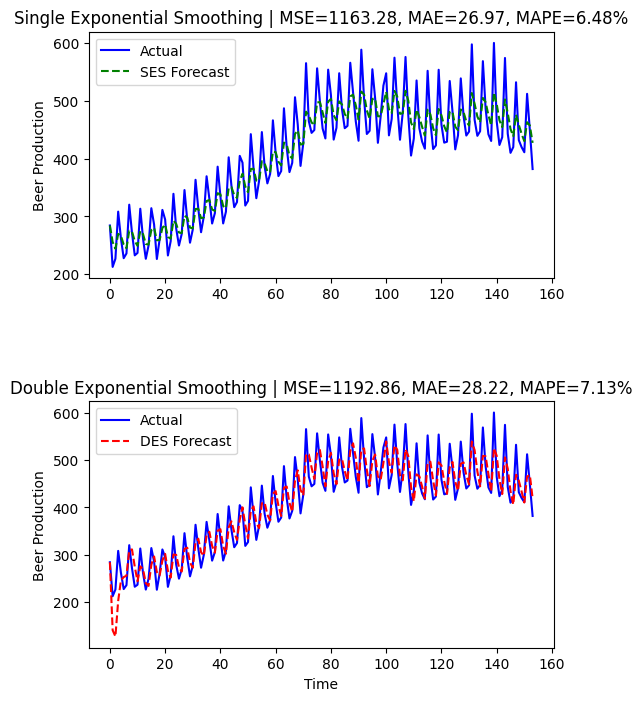

In [35]:
# --- Plot ---
fig = plt.figure(figsize=(6, 8))
fig.subplots_adjust(hspace=0.5)

# SES Plot
ax = fig.add_subplot(2, 1, 1)
y_true.plot(ax=ax, color='b', label="Actual")
beer_df['SES'].plot(ax=ax, color='g', linestyle='--', label="SES Forecast")
ax.set_title(f"Single Exponential Smoothing | MSE={mse_ses:.2f}, MAE={mae_ses:.2f}, MAPE={mape_ses:.2f}%")
ax.set_ylabel("Beer Production")
ax.legend()

# DES Plot
ax = fig.add_subplot(2, 1, 2)
y_true.plot(ax=ax, color='b', label="Actual")
beer_df['DES'].plot(ax=ax, color='r', linestyle='--', label="DES Forecast")
ax.set_title(f"Double Exponential Smoothing | MSE={mse_des:.2f}, MAE={mae_des:.2f}, MAPE={mape_des:.2f}%")
ax.set_xlabel("Time")
ax.set_ylabel("Beer Production")
ax.legend()

plt.show()

# Triple Exponential Smoothing

In [37]:
# Load the dataset
wisc_emp = pd.read_csv('wisconsin-employment-time-series.csv')

# Display first ten records
wisc_emp.head(10)

,Month,Employment
0,1961-01,239.6
1,1961-02,236.4
2,1961-03,236.8
3,1961-04,241.5
4,1961-05,243.7
5,1961-06,246.1
6,1961-07,244.1
7,1961-08,244.2
8,1961-09,244.8
9,1961-10,246.6


In [38]:
print('Shape of the DataFrame:', wisc_emp.shape)

Shape of the DataFrame: (178, 2)


<Axes: >

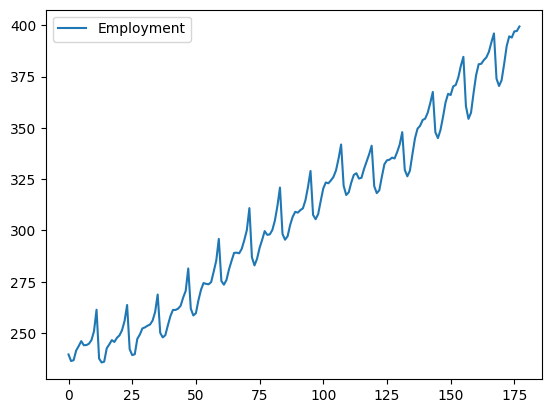

In [39]:
wisc_emp.plot()

In [40]:
es.initialize_T(wisc_emp['Employment'], 12)

1.6916666666666653

In [41]:
es.initialize_seasonalilty(wisc_emp['Employment'], 12) 

{0: np.float64(-11.325000000000006),
 1: np.float64(-14.482142857142861),
 2: np.float64(-12.66785714285715),
 3: np.float64(-6.403571428571437),
 4: np.float64(-1.603571428571436),
 5: np.float64(1.5535714285714246),
 6: np.float64(1.0821428571428495),
 7: np.float64(2.224999999999988),
 8: np.float64(3.5392857142857133),
 9: np.float64(6.896428571428568),
 10: np.float64(11.774999999999993),
 11: np.float64(19.410714285714274)}

In [42]:
# Call Triple exponential smooting for different values of alpha, beta and gamma
wisc_emp['TEF001'] = es.triple_exp_smoothing(wisc_emp['Employment'], 12, 0, 0, 1)
wisc_emp['TEF010'] = es.triple_exp_smoothing(wisc_emp['Employment'], 12, 0, 1, 0)
wisc_emp['TEF100'] = es.triple_exp_smoothing(wisc_emp['Employment'], 12, 1, 0, 0)

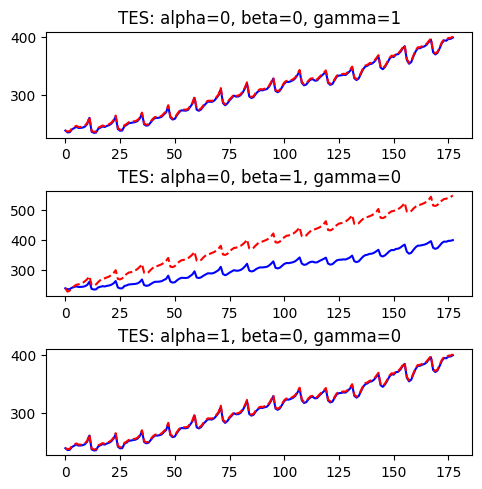

In [43]:
# plot the results for three different cases
fig = plt.figure(figsize=(5.5, 5.5))
ax = fig.add_subplot(3,1,1)
wisc_emp['Employment'].plot(color='b', linestyle = '-', ax=ax)
wisc_emp['TEF001'].plot(color='r', linestyle = '--', ax=ax)
ax.set_title('TES: alpha=0, beta=0, gamma=1')

ax = fig.add_subplot(3,1,2)
wisc_emp['Employment'].plot(color='b', linestyle = '-', ax=ax)
wisc_emp['TEF010'].plot(color='r', linestyle = '--', ax=ax)
ax.set_title('TES: alpha=0, beta=1, gamma=0')

ax = fig.add_subplot(3,1,3)
wisc_emp['Employment'].plot(color='b', linestyle = '-', ax=ax)
wisc_emp['TEF100'].plot(color='r', linestyle = '--', ax=ax)
ax.set_title('TES: alpha=1, beta=0, gamma=0')
fig.subplots_adjust(hspace=.5)
plt.show()

In [44]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# --- Accuracy function ---
def calculate_accuracy(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return mse, mae, mape

In [45]:
# --- TES Forecasts ---
wisc_emp['TEF110'] = es.triple_exp_smoothing(wisc_emp['Employment'], 12, 1, 1, 0)  # α=1, β=1, γ=0
wisc_emp['TEF101'] = es.triple_exp_smoothing(wisc_emp['Employment'], 12, 1, 0, 1)  # α=1, β=0, γ=1
wisc_emp['TEF011'] = es.triple_exp_smoothing(wisc_emp['Employment'], 12, 0, 1, 1)  # α=0, β=1, γ=1

# --- Calculate accuracy ---
mse110, mae110, mape110 = calculate_accuracy(wisc_emp['Employment'], wisc_emp['TEF110'])
mse101, mae101, mape101 = calculate_accuracy(wisc_emp['Employment'], wisc_emp['TEF101'])
mse011, mae011, mape011 = calculate_accuracy(wisc_emp['Employment'], wisc_emp['TEF011'])

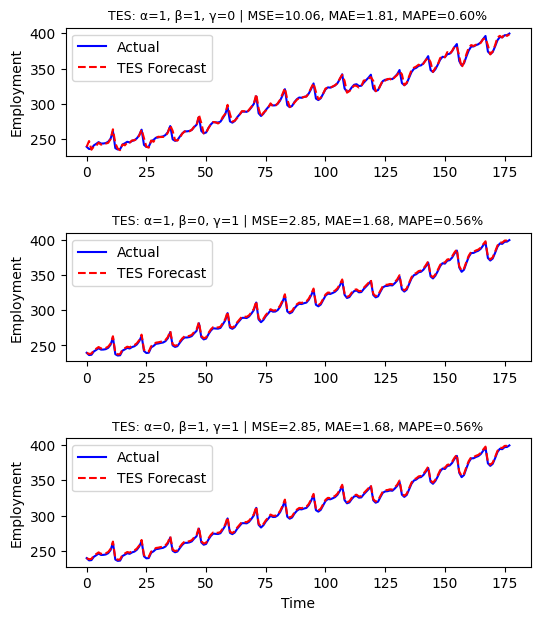

In [46]:
# --- Plot ---
fig = plt.figure(figsize=(6, 7))
fig.subplots_adjust(hspace=0.6)

# TES α=1, β=1, γ=0
ax = fig.add_subplot(3, 1, 1)
wisc_emp['Employment'].plot(color='b', linestyle='-', ax=ax, label="Actual")
wisc_emp['TEF110'].plot(color='r', linestyle='--', ax=ax, label="TES Forecast")
ax.set_title(f"TES: α=1, β=1, γ=0 | MSE={mse110:.2f}, MAE={mae110:.2f}, MAPE={mape110:.2f}%", fontsize=9)
ax.set_ylabel("Employment")
ax.legend()

# TES α=1, β=0, γ=1
ax = fig.add_subplot(3, 1, 2)
wisc_emp['Employment'].plot(color='b', linestyle='-', ax=ax, label="Actual")
wisc_emp['TEF101'].plot(color='r', linestyle='--', ax=ax, label="TES Forecast")
ax.set_title(f"TES: α=1, β=0, γ=1 | MSE={mse101:.2f}, MAE={mae101:.2f}, MAPE={mape101:.2f}%", fontsize=9)
ax.set_ylabel("Employment")
ax.legend()

# TES α=0, β=1, γ=1
ax = fig.add_subplot(3, 1, 3)
wisc_emp['Employment'].plot(color='b', linestyle='-', ax=ax, label="Actual")
wisc_emp['TEF011'].plot(color='r', linestyle='--', ax=ax, label="TES Forecast")
ax.set_title(f"TES: α=0, β=1, γ=1 | MSE={mse011:.2f}, MAE={mae011:.2f}, MAPE={mape011:.2f}%", fontsize=9)
ax.set_xlabel("Time")
ax.set_ylabel("Employment")
ax.legend()

plt.show()


In [47]:
# Add a new column for Triple exponential series
wisc_emp['TES'] = es.triple_exp_smoothing(wisc_emp['Employment'], 12, 0.4, 0.6, 0.2)

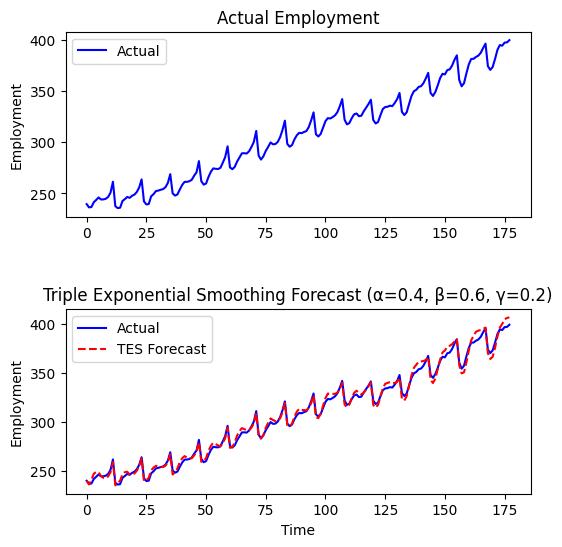

In [48]:
# --- Plot TES results ---
fig = plt.figure(figsize=(6, 6))
fig.subplots_adjust(hspace=0.5)

# Actual Employment
ax = fig.add_subplot(2, 1, 1)
wisc_emp['Employment'].plot(ax=ax, color='b', label="Actual")
ax.set_title('Actual Employment', fontsize=12)
ax.set_ylabel("Employment")
ax.legend()

# TES Forecast vs Actual
ax = fig.add_subplot(2, 1, 2)
wisc_emp['Employment'].plot(ax=ax, color='b', label="Actual")
wisc_emp['TES'].plot(ax=ax, color='r', linestyle="--", label="TES Forecast")
ax.set_title('Triple Exponential Smoothing Forecast (α=0.4, β=0.6, γ=0.2)', fontsize=12)
ax.set_xlabel("Time")
ax.set_ylabel("Employment")
ax.legend()

plt.show()

## Reference:
* Practical Time Series Analysis (Chapter 3), Dr. Avishek Pal, Dr. PKS Prakash, Packt Publishing, September 2017.